# Modellizzazione del rischio RC Auto: costo atteso dei sinistri

Questo progetto analizza il dataset **freMTPL2 (French Motor Third-Party Liability)** con l'obiettivo di stimare il **costo atteso dei sinistri (premio puro)** associato a ciascuna polizza.

L'obiettivo finale è confrontare i modelli attuariali tradizionali con approcci di Machine Learning basati su Gradient Boosting, analizzando il compromesso tra **capacità predittiva e interpretabilità del modello**.

Il progetto è diviso nelle seguenti parti: 

### 1. Modello frequenza–severità
- La **frequenza dei sinistri** viene modellata tramite Poisson GLM e Gradient Boosting con loss function di tipo  Poisson.
- La **severità**, ovvero il costo medio di un sinistro, viene modellata tramite Gamma GLM e Gradient Boosting.
- Le due stime vengono combinate per ottenere il costo atteso dei sinistri:

$$
\underbrace{\mathbb{E}[C_i \mid \mathbf{x}_i]}_{\text{Expected Claims Cost (Pure Premium)}}
=
\underbrace{\mathbb{E}[N_i \mid \mathbf{x}_i]}_{\text{Claim Frequency}}
\times
\underbrace{\mathbb{E}[Y_i \mid N_i > 0, \mathbf{x}_i]}_{\text{Claim Severity}}
$$

dove $\mathbf{x}_i$ sono le caratteristiche della polizza $i$, $C_i$ il costo totale dei sinistri, $N_i$ il numero di sinistri e $Y_i$ il costo di un singolo sinistro, assunto indipendente da $N_i$ dato $\mathbf{x}_i$.

### 2. Segmentazione del rischio
- Le polizze del test set vengono ordinate per **frequenza prevista** e divise in 10 gruppi di rischio crescente.
- Per ogni gruppo si confronta la **frequenza osservata** con quella prevista dal Poisson GLM e dal Gradient Boosting.


### 3. Interpretabilità del modello
- I **GLM** sono interpretabili per costruzione: con la log-link ogni coefficiente si legge come un fattore moltiplicativo, $e^{\beta_j}$, sulla frequenza o sul costo atteso, e la sua significatività è verificabile con un test statistico.
- Il **Gradient Boosting** coglie relazioni non lineari e interazioni tra le variabili, ma non ha coefficienti da leggere: il contributo di ciascuna variabile va ricostruito a posteriori tramite i valori di Shapley (SHAP).
- I due approcci vengono confrontati per verificare se attribuiscono il rischio alle stesse variabili e se il guadagno in capacità predittiva giustifica la perdita di trasparenza, un aspetto rilevante in ambito assicurativo, dove una tariffa deve poter essere spiegata.


## - Introduzione ai dataset

In [75]:
import pandas as pd
import numpy as np
df_freq = pd.read_csv("fremtpl2-french-motor-tpl-insurance-claims/versions/1/freMTPL2freq.csv")
df_freq["IDpol"] = df_freq["IDpol"].astype(int).astype(str)
df_freq.head()

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
3,10,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
4,11,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine


In [76]:
len(df_freq["IDpol"])==len(df_freq["IDpol"].unique())

True

In [77]:
df_sev = pd.read_csv("fremtpl2-french-motor-tpl-insurance-claims/versions/1/freMTPL2sev.csv")
df_sev["IDpol"] = df_sev["IDpol"].astype(str)
df_sev.head()

,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


Text(0.5, 1.0, 'Distribution of claim amounts')

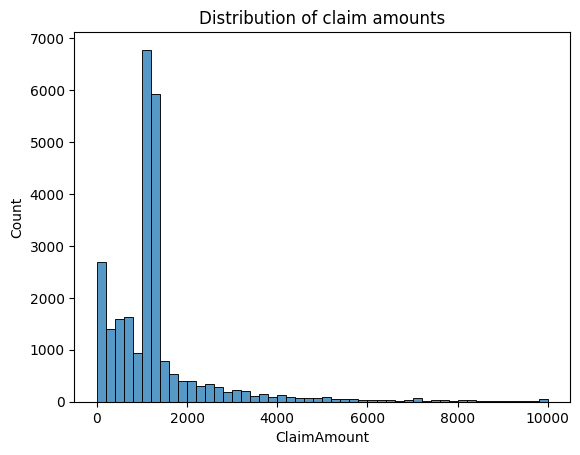

In [78]:
import seaborn as sns

ax = sns.histplot(data=df_sev, x="ClaimAmount", bins=50, binrange=(0, 10000))
ax.set_title("Distribution of claim amounts")



In [79]:
print(f'Quantile a livello .99 per Claim Amount : {df_sev["ClaimAmount"].quantile(0.99):,.2f}')
print(f"Max Claim Amount : {df_sev['ClaimAmount'].max():,.2f}")
print(f'Claim Totali {len(df_sev)}')

Quantile a livello .99 per Claim Amount : 16,793.70
Max Claim Amount : 4,075,400.56
Claim Totali 26639


In [80]:
cap = df_sev["ClaimAmount"].quantile(0.99)

# Gli importi sopra il 99° percentile non vengono eliminati ma limitati a quel valore:
# il sinistro resta nel dataset, con un costo ridotto
df_sev["ClaimAmount"] = df_sev["ClaimAmount"].clip(upper=cap)

In [81]:
# Rimuove le polizze che dichiarano sinistri ma non hanno alcun importo in df_sev,
# così frequenza e severità sono stimate sugli stessi sinistri
has_amount = df_freq["IDpol"].isin(df_sev["IDpol"])
keep = (df_freq["ClaimNb"] == 0) | has_amount
print(f"Polizze rimosse: { (keep == False).sum():,} su {len(df_freq):,}")

df_freq = df_freq[keep]

Polizze rimosse: 9,116 su 678,013


Text(0.5, 1.0, 'Distribution of claim numbers')

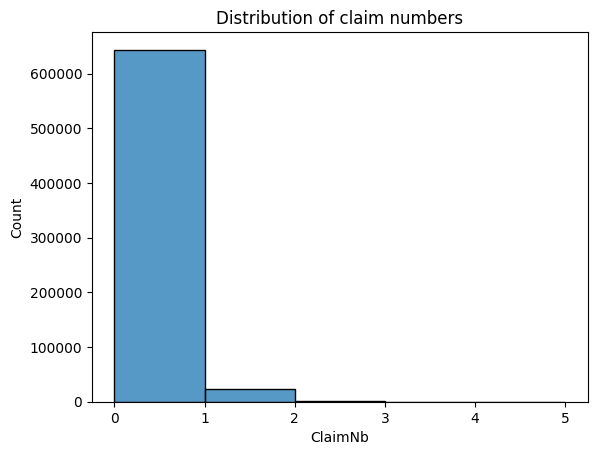

In [82]:
ax = sns.histplot(data=df_freq, x="ClaimNb", bins=5, binrange=(0, 5))
ax.set_title("Distribution of claim numbers")

### Frequenza dei sinistri

Per la polizza $i$: $N_i$ sono i sinistri osservati, $E_i$ l'esposizione in anni e $\lambda_i$ la frequenza annua attesa. Il numero di sinistri è una variabile aleatoria di Poisson:

$$N_i \sim \text{Poisson}(E_i \, \lambda_i)$$

![Distribuzione di Poisson](images/poisson.png)

La frequenza $\lambda_i$ dipende dalle caratteristiche $x_i$ della polizza tramite una log-link:

$$\log \lambda_i = \beta_0 + \beta^\top x_i \quad\Longleftrightarrow\quad \lambda_i = \exp(\beta_0 + \beta^\top x_i)$$

che garantisce una frequenza prevista sempre positiva.

L'esposizione compare come **peso della likelihood**: una polizza osservata più a lungo conta di più nella stima. Il modello è stimato con:

$$\boxed{y_i = \frac{N_i}{E_i}}$$

**Calcolo della log-likelihood.** La probabilità di osservare $N_i$ sinistri è:

$$P(N_i) = \frac{e^{-E_i \lambda_i} \, (E_i \, \lambda_i)^{N_i}}{N_i!}$$

Prendendo il logaritmo:

$$\log P(N_i) = N_i \log \lambda_i - E_i \, \lambda_i + \underbrace{N_i \log E_i - \log N_i!}_{\text{non dipende da } \beta}$$

Sommando sulle polizze e trascurando i termini che non dipendono da $\beta$:

$$\ell(\beta) = \sum_i \left[ N_i \log \lambda_i - E_i \, \lambda_i \right]$$

Sostituendo $N_i = E_i \, y_i$ e raccogliendo $E_i$:

$$\ell(\beta) = \sum_i \left[ E_i \, y_i \log \lambda_i - E_i \, \lambda_i \right] = \sum_i E_i \left[ y_i \log \lambda_i - \lambda_i \right]$$

cioè la log-likelihood di Poisson del target $y_i$, pesata con $w_i = E_i$.


In [86]:
from sklearn.model_selection import train_test_split

TARGET = "ClaimNb"
EXPOSURE = "Exposure"
ID_COL = "IDpol"


feature_cols = [
    col for col in df_freq.columns
    if col not in [TARGET, EXPOSURE, ID_COL]
]

train_idx, test_idx = train_test_split(
    df_freq.index,
    test_size=0.20,
    random_state=42
)

train = df_freq.loc[train_idx].copy()
test = df_freq.loc[test_idx].copy()

X_train = train[feature_cols]
X_test  = test[feature_cols]

exposure_train = train[EXPOSURE]
exposure_test  = test[EXPOSURE]

y_train = train[TARGET]  / exposure_train  # use annualized number of claims
y_test  = test[TARGET] / exposure_test  # use annualized number of claims

In [ ]:
import statsmodels.api as sm
import numpy as np

# Variabili categoriche in dummy e aggiunta dell'intercetta
X_train_glm = sm.add_constant(pd.get_dummies(X_train, drop_first=True, dtype=float))
X_test_glm = sm.add_constant(pd.get_dummies(X_test, drop_first=True, dtype=float))

model = sm.GLM(
    y_train,
    X_train_glm,
    family=sm.families.Poisson(),
    freq_weights = exposure_train
)

result = model.fit()
result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                      y   No. Observations:               535117
Model:                            GLM   Df Residuals:                282910.96
Model Family:                 Poisson   Df Model:                           41
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -81052.
Date:                Tue, 13 Oct 2026   Deviance:                   1.3117e+05
Time:                        07:22:58   Pearson chi2:                 1.01e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01034
Covariance Type:            nonrobust                                         
======================================================================================================
                                         coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
const                                 -4.7064      0.129    -36.436      0.000      -4.960      -4.453
VehPower                               0.0332      0.004      9.008      0.000       0.026       0.040
VehAge                                -0.0172      0.001    -12.027      0.000      -0.020      -0.014
DrivAge                                0.0059      0.001     11.373      0.000       0.005       0.007
BonusMalus                             0.0262      0.000     70.350      0.000       0.025       0.027
Density                              3.04e-06   4.83e-06      0.629      0.529   -6.43e-06    1.25e-05
VehBrand_B10                          -0.0084      0.044     -0.190      0.849      -0.095       0.078
VehBrand_B11                           0.1359      0.047      2.879      0.004       0.043       0.228
VehBrand_B12                          -0.2992      0.025    -12.150      0.000      -0.347      -0.251
VehBrand_B13                           0.0321      0.051      0.634      0.526      -0.067       0.131
VehBrand_B14                          -0.1506      0.097     -1.555      0.120      -0.340       0.039
VehBrand_B2                           -0.0153      0.019     -0.795      0.427      -0.053       0.022
VehBrand_B3                            0.0523      0.027      1.969      0.049       0.000       0.104
VehBrand_B4                            0.0294      0.036      0.809      0.418      -0.042       0.101
VehBrand_B5                            0.0570      0.031      1.843      0.065      -0.004       0.118
VehBrand_B6                            0.0408      0.034      1.185      0.236      -0.027       0.108
VehGas_Regular                        -0.1628      0.014    -11.436      0.000      -0.191      -0.135
Area_B                                 0.0883      0.030      2.993      0.003       0.030       0.146
Area_C                                 0.1524      0.024      6.241      0.000       0.105       0.200
Area_D                                 0.3026      0.026     11.720      0.000       0.252       0.353
Area_E                                 0.3565      0.034     10.544      0.000       0.290       0.423
Area_F                                 0.3469      0.118      2.942      0.003       0.116       0.578
Region_Aquitaine                       0.1030      0.122      0.844      0.398      -0.136       0.342
Region_Auvergne                       -0.0017      0.150     -0.011      0.991      -0.296       0.292
Region_Basse-Normandie                 0.0102      0.129      0.080      0.937      -0.242       0.262
Region_Bourgogne                       0.0422      0.132      0.319      0.750      -0.217       0.301
Region_Bretagne                        0.0239      0.120      0.198      0.843      -0.212      

In [87]:
import sklearn
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, mean_poisson_deviance

# Variabili categoriche convertite in tipo "category", con le stesse categorie su train e test
cat_cols = X_train.select_dtypes("object").columns
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()
for col in cat_cols:
    X_train_xgb[col] = X_train_xgb[col].astype("category")
    X_test_xgb[col] = pd.Categorical(X_test_xgb[col], categories=X_train_xgb[col].cat.categories)

sklearn.set_config(enable_metadata_routing=True)
poisson_scorer = make_scorer(mean_poisson_deviance, greater_is_better=False).set_score_request(sample_weight=True)

freq_grid = {
    "n_estimators": [100, 200,300],
    "max_depth": [3, 4, 6],
    "learning_rate": [0.1, 0.2, 0.3],
}

# Grid search con cross-validation a 3 fold sul train: il test set non viene usato per scegliere i parametri
grid_freq = GridSearchCV(
    xgb.XGBRegressor(objective="count:poisson", enable_categorical=True, tree_method="hist").set_fit_request(sample_weight=True),
    freq_grid,
    scoring=poisson_scorer,
    cv=3,
    verbose=2,
)
grid_freq.fit(X_train_xgb, y_train, sample_weight=exposure_train)

print("Parametri migliori:", grid_freq.best_params_)

# Modello finale: GridSearchCV lo ha già ristimato su tutto il train con i parametri migliori
xgb_model = grid_freq.best_estimator_

Fitting 3 folds for each of 27 candidates, totalling 81 fits
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=100; total time=   0.6s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=100; total time=   0.6s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=100; total time=   0.5s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=200; total time=   0.9s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=200; total time=   0.9s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=200; total time=   0.9s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=300; total time=   1.1s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=300; total time=   1.0s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=300; total time=   1.0s
[CV] END ...learning_rate=0.1, max_depth=4, n_estimators=100; total time=   0.5s
[CV] END ...learning_rate=0.1, max_depth=4, n_estimators=100; total time=   0.7s
[CV] END ...learning_rate=0.1, max_depth=4, n_es

In [88]:
from sklearn.metrics import mean_poisson_deviance, mean_absolute_error

# Frequenza annua prevista sul test set
pred_glm = result.predict(X_test_glm)
pred_xgb = xgb_model.predict(X_test_xgb)

for name, pred in [("Poisson GLM", pred_glm), ("XGBoost", pred_xgb)]:
    claims_pred = pred * exposure_test  # sinistri attesi nel periodo osservato
    deviance = mean_poisson_deviance(test["ClaimNb"], claims_pred) # differenza della log-likelyhood con il modello saturato
    mae = mean_absolute_error(test["ClaimNb"], claims_pred)
    print(f"{name}: devianza = {deviance:.4f}, MAE = {mae:.4f}, sinistri previsti totali = {claims_pred.sum():,.0f}")
    

print(f"Sinistri osservati realmente = {test['ClaimNb'].sum():,}")

Poisson GLM: devianza = 0.2463, MAE = 0.0744, sinistri previsti totali = 5,283
XGBoost: devianza = 0.2409, MAE = 0.0736, sinistri previsti totali = 5,287
Sinistri osservati realmente = 5,371


### Severità dei sinistri

La severità è il costo $Y_i$ di un singolo sinistro. È osservata solo per le polizze con almeno un sinistro ($N_i > 0$), quindi il modello è stimato sui soli sinistri, una riga per sinistro.

**Perché una Gamma.** Gli importi dei sinistri sono:

- **strettamente positivi e continui**, mentre una Normale ammetterebbe valori negativi;
- **asimmetrici a destra**: molti sinistri piccoli e pochi molto costosi, come mostra l'istogramma iniziale;
- **più variabili quando sono più grandi**: nella Gamma la varianza cresce con il quadrato della media.

$$Y_i \sim \text{Gamma}(\mu_i, \phi), \qquad \mathbb{E}[Y_i] = \mu_i, \qquad \text{Var}(Y_i) = \phi \, \mu_i^2$$

![Distribuzione Gamma](images/gamma.png)

Come per la frequenza, la media è modellata con una log-link:

$$\log \mu_i = \alpha_0 + \alpha^\top x_i$$

che garantisce importi previsti positivi e continui.


In [ ]:
# Un sinistro per riga, con la stessa suddivisione train/test usata per la frequenza
sev_train = train.merge(df_sev, on="IDpol", how="inner")
sev_test = test.merge(df_sev, on="IDpol", how="inner")

# Variabili categoriche in dummy e aggiunta dell'intercetta
X_sev_train = sm.add_constant(pd.get_dummies(sev_train[feature_cols], drop_first=True, dtype=float))
X_sev_test = sm.add_constant(pd.get_dummies(sev_test[feature_cols], drop_first=True, dtype=float))

gamma_model = sm.GLM(
    sev_train["ClaimAmount"],
    X_sev_train,
    family=sm.families.Gamma(link=sm.families.links.Log())
)

gamma_result = gamma_model.fit()
gamma_result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:            ClaimAmount   No. Observations:                21073
Model:                            GLM   Df Residuals:                    21031
Model Family:                   Gamma   Df Model:                           41
Link Function:                    Log   Scale:                          1.9776
Method:                          IRLS   Log-Likelihood:            -1.7932e+05
Date:                Mon, 12 Oct 2026   Deviance:                       21551.
Time:                        22:11:46   Pearson chi2:                 4.16e+04
No. Iterations:                    13   Pseudo R-squ. (CS):           0.006048
Covariance Type:            nonrobust                                         
======================================================================================================
                                         coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
const                                  6.9620      0.182     38.278      0.000       6.606       7.318
VehPower                               0.0056      0.005      1.088      0.277      -0.005       0.016
VehAge                                -0.0070      0.002     -3.373      0.001      -0.011      -0.003
DrivAge                                0.0009      0.001      1.160      0.246      -0.001       0.002
BonusMalus                             0.0030      0.001      5.353      0.000       0.002       0.004
Density                             3.057e-06   6.85e-06      0.447      0.655   -1.04e-05    1.65e-05
VehBrand_B10                           0.1403      0.062      2.263      0.024       0.019       0.262
VehBrand_B11                           0.0499      0.066      0.755      0.450      -0.080       0.179
VehBrand_B12                           0.0265      0.034      0.769      0.442      -0.041       0.094
VehBrand_B13                           0.0070      0.071      0.098      0.922      -0.133       0.147
VehBrand_B14                          -0.0324      0.136     -0.238      0.812      -0.299       0.235
VehBrand_B2                         9.993e-05      0.027      0.004      0.997      -0.053       0.053
VehBrand_B3                            0.0053      0.037      0.143      0.886      -0.068       0.079
VehBrand_B4                           -0.0871      0.051     -1.702      0.089      -0.187       0.013
VehBrand_B5                           -0.0290      0.044     -0.668      0.504      -0.114       0.056
VehBrand_B6                           -0.0245      0.048     -0.505      0.613      -0.119       0.070
VehGas_Regular                        -0.0067      0.020     -0.334      0.738      -0.046       0.033
Area_B                                 0.0463      0.042      1.115      0.265      -0.035       0.128
Area_C                                -0.0055      0.034     -0.159      0.874      -0.073       0.062
Area_D                                 0.0168      0.036      0.466      0.642      -0.054       0.088
Area_E                                 0.0073      0.047      0.154      0.878      -0.086       0.100
Area_F                                -0.1896      0.167     -1.134      0.257      -0.517       0.138
Region_Aquitaine                       0.1974      0.172      1.150      0.250      -0.139       0.534
Region_Auvergne                       -0.1778      0.211     -0.843      0.399      -0.591       0.236
Region_Basse-Normandie                 0.0823      0.181      0.455      0.649      -0.272       0.437
Region_Bourgogne                       0.1609      0.186      0.866      0.387      -0.203       0.525
Region_Bretagne                        0.1595      0.169      0.943      0.346      -0.172      

In [ ]:
# Variabili categoriche convertite in tipo "category", con le stesse categorie usate per la frequenza
X_sev_train_xgb = sev_train[feature_cols].copy()
X_sev_test_xgb = sev_test[feature_cols].copy()
for col in cat_cols:
    X_sev_train_xgb[col] = pd.Categorical(X_sev_train_xgb[col], categories=X_train_xgb[col].cat.categories)
    X_sev_test_xgb[col] = pd.Categorical(X_sev_test_xgb[col], categories=X_train_xgb[col].cat.categories)

sev_grid = {
    "n_estimators": [100, 200,300],
    "max_depth": [3, 4, 6],
    "learning_rate": [0.1, 0.2, 0.3],
}
# Grid search con cross-validation a 3 fold sui sinistri di train
grid_sev = GridSearchCV(
    xgb.XGBRegressor(objective="reg:gamma", enable_categorical=True, tree_method="hist"),
    sev_grid,
    scoring="neg_mean_gamma_deviance",
    cv=3,
    verbose=1,
)
grid_sev.fit(X_sev_train_xgb, sev_train["ClaimAmount"])

print("Parametri migliori:", grid_sev.best_params_)
print(f"Devianza media in cross-validation: {-grid_sev.best_score_:.4f}")

# Modello finale: GridSearchCV lo ha già ristimato su tutti i sinistri di train con i parametri migliori
xgb_sev_model = grid_sev.best_estimator_

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Parametri migliori: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Devianza media in cross-validation: 1.0360


In [ ]:
from sklearn.metrics import mean_gamma_deviance, mean_absolute_error

# Costo previsto per sinistro sul test set
pred_sev_glm = gamma_result.predict(X_sev_test)
pred_sev_xgb = xgb_sev_model.predict(X_sev_test_xgb)

for name, pred in [("Gamma GLM", pred_sev_glm), ("XGBoost", pred_sev_xgb)]:
    deviance = mean_gamma_deviance(sev_test["ClaimAmount"], pred) # differenza della log-likelyhood con il modello saturato
    mae = mean_absolute_error(sev_test["ClaimAmount"], pred)
    print(f"{name}: devianza = {deviance:.4f}, MAE = {mae:,.2f}, costo previsto totale = {pred.sum():,.0f}")


print(f"Costo osservato realmente = {sev_test['ClaimAmount'].sum():,.0f}")

Gamma GLM: devianza = 1.0833, MAE = 1,126.03, costo previsto totale = 8,395,650
XGBoost: devianza = 1.0989, MAE = 1,112.99, costo previsto totale = 8,264,548
Costo osservato realmente = 8,587,317


### Costo atteso dei sinistri (premio puro)

Le due stime vengono ora combinate. Per ogni polizza del test set il costo atteso nel periodo osservato è:

$$\hat{C}_i = E_i \, \hat{\lambda}_i \, \hat{\mu}_i$$

dove $E_i$ è l'esposizione, $\hat{\lambda}_i$ la frequenza annua prevista e $\hat{\mu}_i$ il costo previsto per sinistro. Il modello di severità, stimato sui soli sinistri, viene applicato a tutte le polizze di test, perché dipende solo dalle loro caratteristiche.

Il totale previsto viene confrontato con il costo effettivamente osservato sulle stesse polizze, con gli importi limitati al 99° percentile come nel modello di severità.


In [ ]:
# Costo totale osservato sul test set: somma degli importi dei sinistri delle polizze di test
cost_observed = sev_test["ClaimAmount"].sum()

# Costo previsto per sinistro, per tutte le polizze di test
sev_glm = gamma_result.predict(X_test_glm)
sev_xgb = xgb_sev_model.predict(X_test_xgb)

for name, freq, sev in [("GLM", pred_glm, sev_glm), ("XGBoost", pred_xgb, sev_xgb)]:
    cost_pred = (freq * exposure_test * sev).sum()  # esposizione x frequenza x severità
    perc_error = (cost_pred - cost_observed) / cost_observed * 100  # errore percentuale: negativo = sottostima
    print(f"{name}: costo previsto totale = {cost_pred:,.0f}, errore percentuale = {perc_error:+.2f}%")

print(f"Costo osservato totale = {cost_observed:,.0f}")

GLM: costo previsto totale = 8,276,122, errore percentuale = -3.62%
XGBoost: costo previsto totale = 8,119,668, errore percentuale = -5.45%
Costo osservato totale = 8,587,317


### Segmentazione del rischio - Frequency risk


1. le polizze vengono ordinate per frequenza prevista dal Poisson GLM e divise in **10 gruppi** di uguale numerosità (gruppo 1 = meno rischioso, gruppo 10 = più rischioso). Gli stessi gruppi sono usati per entrambi i modelli, così le tre serie sono confrontate sulle stesse polizze;
2. per ogni gruppo $g$ si confrontano la frequenza osservata e quella prevista, calcolate come sinistri totali su esposizione totale:

$$\text{frequenza osservata}_g = \frac{\sum_{i \in g} N_i}{\sum_{i \in g} E_i}, \qquad \text{frequenza prevista}_g = \frac{\sum_{i \in g} E_i \, \hat{\lambda}_i}{\sum_{i \in g} E_i}$$


In [ ]:
seg = pd.DataFrame({
    "ClaimNb": test["ClaimNb"],
    "Exposure": exposure_test,
    "freq_glm": pred_glm,
    "freq_xgb": pred_xgb,
})

# Risk deciles based on predicted annual frequency
seg["gruppo"] = pd.qcut(
    seg["freq_glm"],
    q=10,
    labels=range(1, 11),
    duplicates="drop"
)

seg["claims_pred_glm"] = seg["freq_glm"] * seg["Exposure"]
seg["claims_pred_xgb"] = seg["freq_xgb"] * seg["Exposure"]

table = seg.groupby("gruppo", observed=True).agg(
    ClaimNb=("ClaimNb", "sum"),
    Exposure=("Exposure", "sum"),
    previsti_glm=("claims_pred_glm", "sum"),
    previsti_xgb=("claims_pred_xgb", "sum")
)

seg_table = pd.DataFrame({
    "Osservata": table["ClaimNb"] / table["Exposure"],
    "Poisson GLM": table["previsti_glm"] / table["Exposure"],
    "XGBoost": table["previsti_xgb"] / table["Exposure"],
})

seg_table.round(4)


,Osservata,Poisson GLM,XGBoost
gruppo,,,
1,0.0361,0.0390,0.0378
2,0.0437,0.0467,0.0448
3,0.0502,0.0518,0.0500
4,0.0546,0.0565,0.0554
5,0.0597,0.0615,0.0614
6,0.0702,0.0674,0.0690
7,0.0839,0.0753,0.0795
8,0.0968,0.0877,0.0950
9,0.1192,0.1129,0.1162


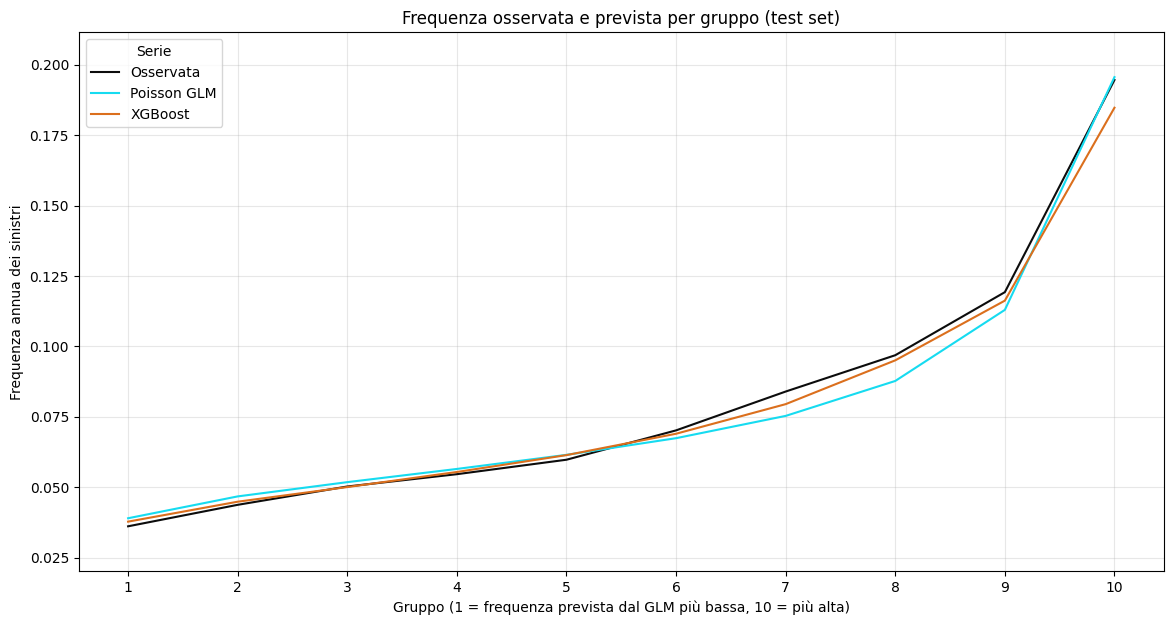

In [ ]:
import matplotlib.pyplot as plt
 
# Frequenza osservata e prevista dai due modelli, sugli stessi 10 gruppi
plot_data = seg_table.reset_index().melt(id_vars="gruppo", var_name="Serie", value_name="frequenza")
plot_data["gruppo"] = plot_data["gruppo"].astype(int)
ymin = plot_data["frequenza"].min()
ymax = plot_data["frequenza"].max()
margin = (ymax - ymin) * 0.1

plt.figure(figsize=(14, 7))
ax = sns.lineplot(
    data=plot_data, x="gruppo", y="frequenza", hue="Serie",
    palette={ "Poisson GLM": "#16dbf0", "XGBoost": "#db6f1d","Osservata": "#0C0C0C"},
)
ax.set_ylim(ymin - margin, ymax + margin)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Gruppo (1 = frequenza prevista dal GLM più bassa, 10 = più alta)")
ax.set_ylabel("Frequenza annua dei sinistri")
ax.set_title("Frequenza osservata e prevista per gruppo (test set)")
ax.grid(True, alpha=0.3)

plt.show()

### Interpretabilità del modello per la frequenza

Quest'ultima parte confronta **come** i due modelli di frequenza arrivano alle loro previsioni.

**Poisson GLM.** Il modello è interpretabile direttamente attraverso i coefficienti:

$$\log \hat{\lambda}_i = \beta_0 + \sum_j \beta_j \, x_{ij}$$

dove $e^{\beta_j}$ è il **rate ratio** associato a un incremento unitario di $x_j$: il fattore per cui si moltiplica la frequenza prevista. L'effetto è globale, cioè uguale per tutte le polizze.

La tabella che segue riporta, per le variabili numeriche, il coefficiente $\beta_j$ stimato, il corrispondente rate ratio $e^{\beta_j}$ e il p-value. Ogni coefficiente è riferito a un aumento di un'unità della variabile (un punto di bonus-malus, un anno di età), quindi la sua grandezza dipende dall'unità di misura.

**XGBoost.** Non ha coefficienti da leggere, quindi le sue previsioni vengono spiegate con i **valori di Shapley** (SHAP values). Per ogni polizza $i$:

$$\log \hat{\lambda}_i = \phi_0 + \sum_j \phi_{ij}$$

dove $\phi_0$ è il valore di base, uguale per tutte le polizze, e $\phi_{ij}$ è il contributo della variabile $j$ alla previsione della polizza $i$. Un valore positivo aumenta la frequenza prevista rispetto al valore di base, uno negativo la riduce; $e^{\phi_{ij}}$ è il corrispondente fattore moltiplicativo.

A differenza dei coefficienti del GLM, i contributi SHAP sono **locali**: cambiano da osservazione a osservazione.



In [ ]:
# Coefficienti stimati del Poisson GLM per le variabili numeriche
num_cols = X_train.select_dtypes("number").columns

pd.DataFrame({
    "coefficiente": result.params[num_cols],
    "rate ratio": np.exp(result.params[num_cols]),
    "p-value": result.pvalues[num_cols],
}).round(4)

,coefficiente,rate ratio,p-value
VehPower,0.0332,1.0338,0.0000
VehAge,-0.0172,0.9829,0.0000
DrivAge,0.0059,1.0059,0.0000
BonusMalus,0.0262,1.0265,0.0000
Density,0.0000,1.0000,0.5291


In [ ]:
import shap

# SHAP values calcolati direttamente da XGBoost
contribs = xgb_model.get_booster().predict(
    xgb.DMatrix(X_test_xgb, enable_categorical=True),
    pred_contribs=True
)

# Crea oggetto SHAP
shap_values = shap.Explanation(
    values=contribs[:, :-1],
    base_values=contribs[:, -1],
    data=X_test_xgb.apply(
        lambda x: x.cat.codes if x.dtype.name == "category" else x
    ).values,
    feature_names=X_test_xgb.columns
)


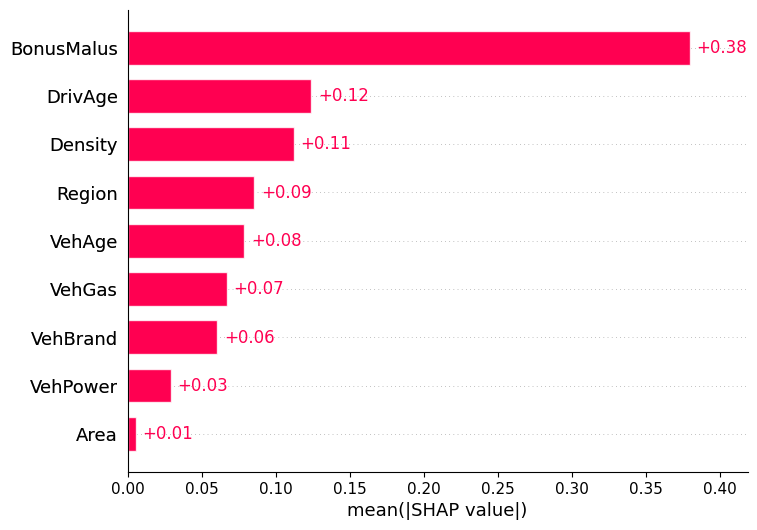

In [ ]:
shap.plots.bar(shap_values)

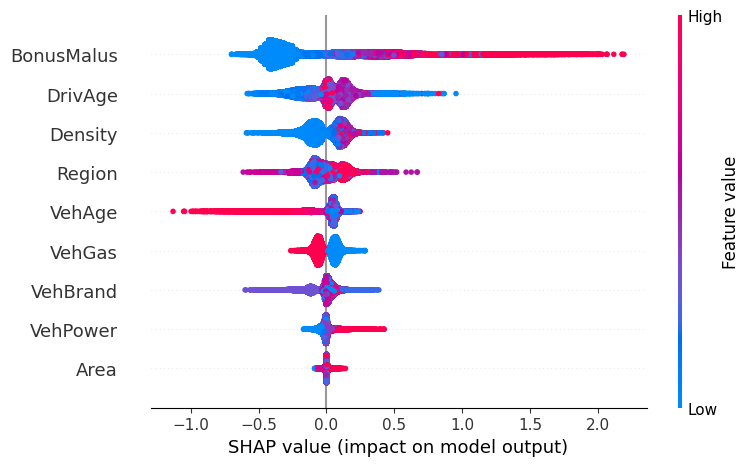

In [ ]:
shap.plots.beeswarm(shap_values)

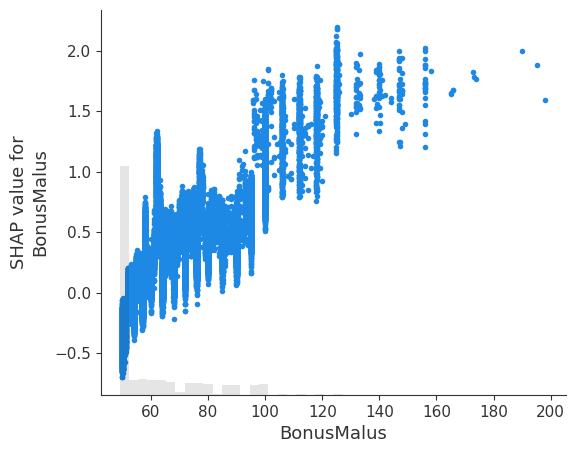

In [ ]:
shap.plots.scatter(shap_values[:, 3]) # Marginal contribution of Bonus Malus

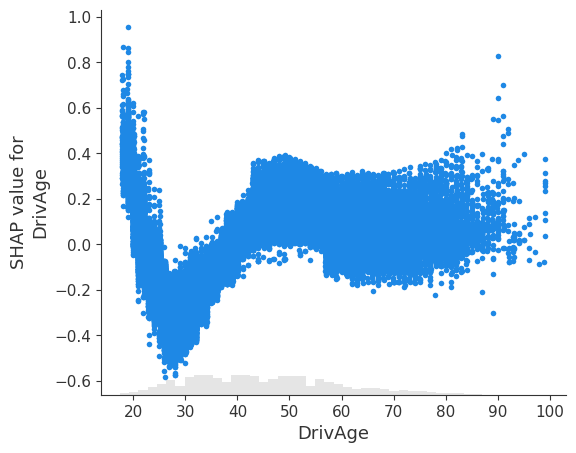

In [ ]:
shap.plots.scatter(shap_values[:, 2]) # Marginal contribution of Driver Age

### Conclusioni

**Analisi variabili** .

- **Bonus-malus** è la variabile più importante per entrambi i modelli.
- **Età del conducente**: il GLM stima un effetto lineare (+0,59% per anno), mentre SHAP mostra un rischio alto sotto i 25 anni e minimo intorno ai 30.
- **Territorio**: il GLM lo coglie con `Area`, XGBoost con `Density`. Le due variabili misurano lo stesso fenomeno.

**Il guadagno predittivo giustifica la perdita di trasparenza?** Su questi dati è limitato.

- **Frequenza**: XGBoost è migliore (devianza 0,2409 contro 0,2463).
- **Severità**: il Gamma GLM è migliore (devianza 1,083 contro 1,099).
- **Costo totale**: entrambi sottostimano, il GLM del 3,6% e XGBoost del 5,5%.

Per una tariffa che deve poter essere spiegata il GLM resta la scelta più solida. XGBoost con SHAP è utile per individuare gli effetti non lineari, come quello dell'età, che il GLM non coglie.
